In [12]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns


# explication donnée de ce csv 
relative_path = "../../data/raw/expression/tcga_gbm_gper_clinical.csv"

absolute_path = os.path.abspath(relative_path)
fichier = pd.read_csv(absolute_path)
df = pd.DataFrame(fichier)

print(df.head())

        Unnamed: 0    GPER    ESR1    ESR2  \
0  TCGA-27-1832-01  7.6221  5.5975  6.4247   
1  TCGA-27-1831-01  6.2182  4.5914  2.5733   
2  TCGA-28-5216-01  7.0905  3.4280  3.9676   
3  TCGA-16-0846-01  8.5181  4.5453  3.7043   
4  TCGA-28-5218-01  6.8624  3.9839  2.4623   

   age_at_initial_pathologic_diagnosis  gender    sample_type  
0                                 59.0  FEMALE  Primary Tumor  
1                                 66.0    MALE  Primary Tumor  
2                                 52.0    MALE  Primary Tumor  
3                                 85.0    MALE  Primary Tumor  
4                                 63.0    MALE  Primary Tumor  


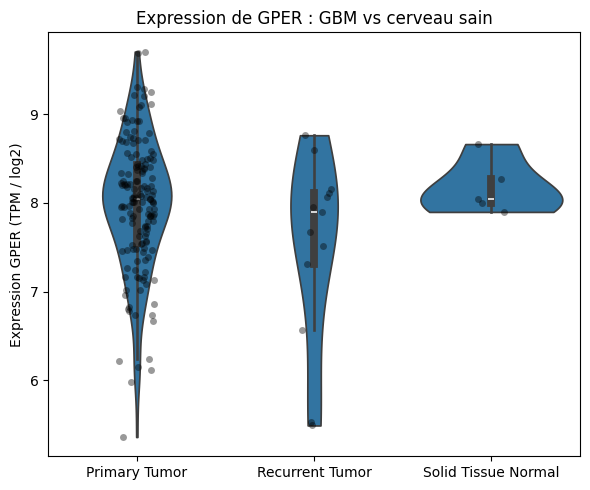

In [13]:
plt.figure(figsize=(6,5))
sns.violinplot(data=df,
    x="sample_type",
    y="GPER",
    inner="box",
    cut=0
)
sns.stripplot(
    data=df,
    x="sample_type",
    y="GPER",
    color="black",
    alpha=0.4
)

plt.title("Expression de GPER : GBM vs cerveau sain")
plt.ylabel("Expression GPER (TPM / log2)")
plt.xlabel("")
plt.tight_layout()
plt.show()

-->  L'axe vertical (Y) : Il mesure le niveau d'expression du gène GPER. L'unité est en "TPM / log2" (une échelle logarithmique de la quantité d'ARN). Plus le point est haut, plus le gène est exprimé (actif) ; plus il est bas, moins il est exprimé.

-->  L'axe horizontal (X) : Il sépare les échantillons en trois catégories :

    Primary Tumor : Tumeur primitive (le cancer initial).

    Recurrent Tumor : Tumeur récidivante (le cancer qui est revenu après traitement).

    Solid Tissue Normal : Tissu cérébral sain (généralement prélevé en marge de la tumeur).



Ce graphique suggère que l'expression du gène GPER est dérégulée dans le glioblastome.

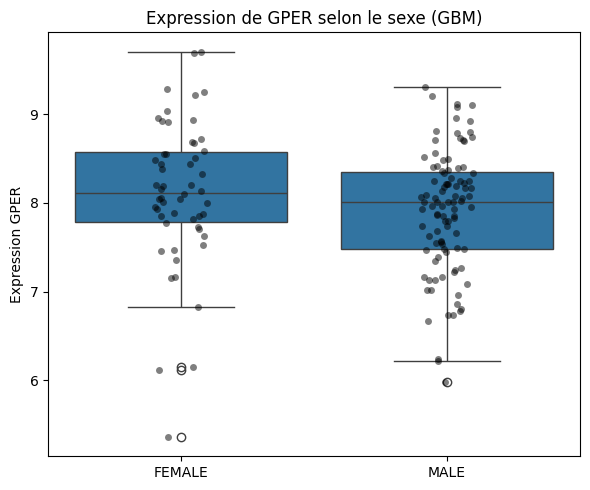

In [14]:
df_gbm = df[df["sample_type"] == "Primary Tumor"]

plt.figure(figsize=(6,5))
sns.boxplot(
    data=df_gbm,
    x="gender",
    y="GPER"
)
sns.stripplot(
    data=df_gbm,
    x="gender",
    y="GPER",
    color="black",
    alpha=0.5
)

plt.title("Expression de GPER selon le sexe (GBM)")
plt.ylabel("Expression GPER")
plt.xlabel("")
plt.tight_layout()
plt.show()

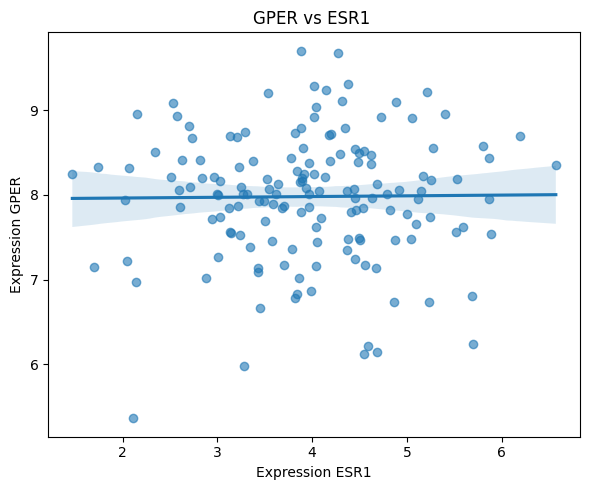

In [18]:

plt.figure(figsize=(6,5))
sns.regplot(
    data=df_gbm,
    x="ESR1",
    y="GPER",
    scatter_kws={"alpha":0.6}
)

plt.title("GPER vs ESR1 ")
plt.xlabel("Expression ESR1")
plt.ylabel("Expression GPER")
plt.tight_layout()
plt.show()

Indépendance des gènes : Le fait que la ligne soit plate indique que le niveau d'expression d'ESR1 n'influence pas (ou n'est pas lié à) le niveau d'expression de GPER.

Imprévisibilité : Si vous savez qu'un patient a un niveau élevé d'ESR1, cela ne vous permet pas de prédire s'il aura un niveau élevé ou faible de GPER. Les deux varient de manière indépendante

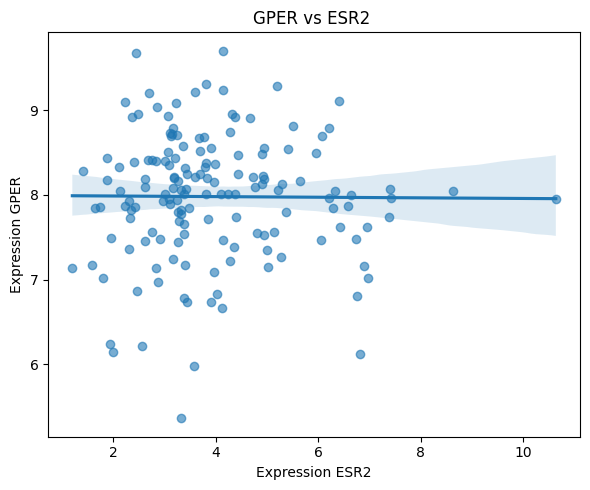

In [20]:

plt.figure(figsize=(6,5))
sns.regplot(
    data=df_gbm,
    x="ESR2",
    y="GPER",
    scatter_kws={"alpha":0.6}
)

plt.title("GPER vs ESR2 ")
plt.xlabel("Expression ESR2")
plt.ylabel("Expression GPER")
plt.tight_layout()
plt.show()

L'expression de GPER est indépendante des récepteurs aux œstrogènes classiques (ESR1 et ESR2).

Cela signifie que GPER ne fait pas simplement partie d'un "bloc" de gènes d'œstrogènes qui seraient tous activés ou désactivés en même temps.

Il possède probablement ses propres mécanismes de régulation spécifiques dans la tumeur, distincts de ceux des récepteurs nucléaires classiques (ESR1/ESR2).

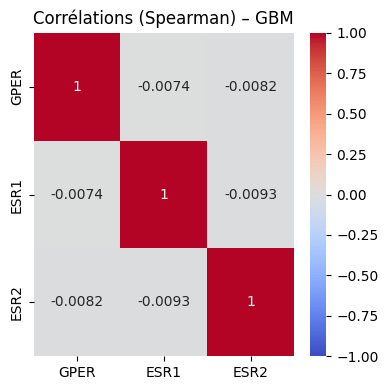

In [21]:
genes = ["GPER", "ESR1", "ESR2"]
corr = df_gbm[genes].corr(method="spearman")

plt.figure(figsize=(4,4))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Corrélations (Spearman) – GBM")
plt.tight_layout()
plt.show()

In [ ]:
Indépendance totale : L'expression de GPER n'a strictement aucun lien avec celle d'ESR1 ou d'ESR2 dans le Glioblastome. 
Savoir combien il y a de récepteurs ESR1 ne vous donne aucun indice sur la quantité de GPER.

Dysrégulation : Même entre eux, ESR1 et ESR2 ne semblent pas corrélés (valeur de -0.0093), ce qui suggère que toute la machinerie des récepteurs 
aux œstrogènes est complètement désynchronisée ou dérégulée dans ces tumeurs.

AINSI  
-GPER est plus exprimé chez les femmes
-GPER n’est pas corrélé à ESR1 ni ESR2


donc pour notre graphe on doit favoriser les GPCR qui :

-ne sont pas co-exprimés avec ESR1/ESR2
-mais co-exprimés avec GPER chez les femmes